# Zgodność anotacji - nowy prompt etapu 1 (Wykop, próba 2)

Druga runda walidacji, na nowej próbie 150 wpisów, na której nic nie było dostrajane.
Dwie osoby (Zuza, Mikołaj) oznaczyły ją na ślepo etykietami etapu 1 według aktualnych
wytycznych (`docs/wykop/annotation-guidelines.md`). Porównujemy je ze sobą i z modelem
`qwen3:8b` z **nowym promptem etapu 1** (`amc/classification/job_concern.py`).

- `ai` - czy wpis dotyczy sztucznej inteligencji (`yes`/`no`),
- `work` - czy wpis dotyczy pracy, kariery lub rynku pracy (`yes`/`no`),
- `ai+work` - obie naraz; to filtr, który decyduje, co trafia do etapu 2.

Punkt odniesienia: etykiety **starego promptu** (`72f3a1da`) dla tych samych wpisów, z pliku
`wykop_sample_2_key.csv`. Próba była losowana pół na pół z wpisów, które stary prompt oznaczył
jako `ai`+`work` i z pozostałych, więc wpisów o AI i pracy jest w niej więcej niż w całym
zbiorze. Przy dwóch anotatorach etykieta złota istnieje tylko tam, gdzie oboje się zgadzają.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from amc.classification.job_concern import PROMPT_HASH, YES_NO  # noqa: E402
from amc.classification.job_concern_details import STANCE  # noqa: E402

pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.figsize"] = (10, 4)

DATA = Path("../data/wykop")
KEY = ["type", "entry_id"]
SEED = 20261025
CATEGORIES = {"ai": YES_NO, "work": YES_NO, "ai+work": YES_NO, "stance": STANCE}

## Konfiguracja

In [2]:
ANNOTATION_FILES = {
    "Zuza": DATA / "wykop_sample_2_Zuza.xlsx",
    "Mikołaj": DATA / "wykop_sample_2_mikolaj.xlsx",
}
LABELS = ["ai", "work"]  # etykiety anotatorów
MODEL_FILE = DATA / "wykop_stage1.csv"
MODEL_PROMPT = PROMPT_HASH  # aktualny prompt etapu 1
MODEL_LABELS = ["ai", "work"]
BASELINE = (DATA / "wykop_sample_2_key.csv", "stary prompt")
OUT = DATA / "agreement" / "new_prompt"

## Wczytanie danych

In [3]:
def clean(df, labels):
    """Etykiety małymi literami; wartości spoza słownika (np. puste) stają się brakiem."""
    df = df.reset_index(drop=True).copy()
    for label in labels:
        values = df[label].fillna("").astype(str).str.strip().str.lower()
        df[label] = values.where(values.isin(CATEGORIES[label]))
    if "ai" in labels and "work" in labels:
        both = df["ai"].eq("yes") & df["work"].eq("yes")
        df["ai+work"] = np.where(both, "yes", "no")
        df.loc[df["ai"].isna() | df["work"].isna(), "ai+work"] = np.nan
    return df


def load_annotations(path):
    df = pd.read_excel(path, sheet_name="sample", dtype=str).dropna(subset=["entry_id"])
    return clean(df, LABELS)


OUT.mkdir(parents=True, exist_ok=True)
sheets = {name: load_annotations(path) for name, path in ANNOTATION_FILES.items()}
ANNOTATORS = list(sheets)
base = sheets[ANNOTATORS[0]][[*KEY, "created_at", "url", "text"]]
for name, df in sheets.items():
    assert df[KEY].equals(base[KEY]), f"{name}: inne wpisy lub kolejność"
    missing = df[LABELS].isna().sum()
    if missing.any():
        print(f"{name}: brak poprawnej odpowiedzi -> {missing[missing > 0].to_dict()}")
print("wpisów:", len(base), "| anotatorzy:", ANNOTATORS)


def load_labels(path, labels, prompt=None):
    df = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
    if prompt is not None:
        df = df[df["prompt_hash"].str.startswith(prompt)]
    df = base[KEY].merge(df, on=KEY, how="left", validate="one_to_one")
    assert df[labels[0]].notna().all(), f"{path.name}: brak etykiet dla części wpisów"
    return clean(df, labels)


ratings = dict(sheets)
model = load_labels(MODEL_FILE, MODEL_LABELS, MODEL_PROMPT)
ratings["model"] = model
print("model:", model["model"].dropna().unique(), "| prompt:", MODEL_PROMPT[:8])
if BASELINE is not None:
    ratings[BASELINE[1]] = load_labels(BASELINE[0], ["ai", "work"])
RATERS = list(ratings)
ALL_LABELS = [*LABELS[:2], "ai+work", *LABELS[2:]] if "work" in LABELS else LABELS


def raters_for(label):
    return [r for r in RATERS if label in ratings[r].columns]

Mikołaj: brak poprawnej odpowiedzi -> {'ai': 1, 'work': 1}
wpisów: 150 | anotatorzy: ['Zuza', 'Mikołaj']
model: ['qwen3:8b'] | prompt: 323c0eeb


## Rozkład etykiet

In [4]:
pd.concat(
    {
        label: pd.DataFrame(
            {r: ratings[r][label].value_counts() for r in raters_for(label)}
        ).reindex(CATEGORIES[label])
        for label in ALL_LABELS
    }
).astype("Int64")

Zuza  Mikołaj  model  stary prompt
        ai                                     
ai      yes    62       53     73            80
        no     88       96     77            70
work    yes   117       98    114           122
        no     33       51     36            28
ai+work yes    45       39     51            75
        no    105      110     99            75

## Miary zgodności

- **zgodność %** - odsetek par ocen, które są takie same;
- **kappa Cohena** - dla pary oceniających (także model z człowiekiem), z poprawką na
  zgodność przypadkową wynikającą z rozkładu etykiet każdego z nich;
- **kappa Fleissa** - jedna liczba dla wszystkich anotatorów naraz.

Przedziały ufności 95% z bootstrapu po wpisach (2000 losowań). Wpisy z brakującą odpowiedzią
są pomijane tylko w porównaniach, których dotyczą.

In [5]:
def labels_of(label, raters):
    """Macierz wpis x oceniający; wiersze z jakimkolwiek brakiem są pomijane."""
    values = pd.concat([ratings[r][label].rename(r) for r in raters], axis=1).dropna()
    return values.to_numpy(dtype=object), values.index


def percent_agreement(values):
    """Odsetek zgodnych par ocen; dla dwóch oceniających to odsetek identycznych ocen."""
    m = values.shape[1]
    counts = np.stack([(values == c).sum(axis=1) for c in np.unique(values)], axis=1)
    return (((counts**2).sum(axis=1) - m) / (m * (m - 1))).mean()


def cohen_kappa(values):
    a, b = values[:, 0], values[:, 1]
    p_o = np.mean(a == b)
    p_e = sum(np.mean(a == c) * np.mean(b == c) for c in np.union1d(a, b))
    return (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan


def fleiss_kappa(values):
    counts = np.stack([(values == c).sum(axis=1) for c in np.unique(values)], axis=1)
    p_e = ((counts.sum(axis=0) / counts.sum()) ** 2).sum()
    p_o = percent_agreement(values)
    return (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan


def bootstrap(statistic, values, iterations=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    draws = [
        statistic(values[rng.integers(0, len(values), len(values))]) for _ in range(iterations)
    ]
    low, high = np.nanpercentile(draws, [2.5, 97.5])
    return f"[{low:.2f}, {high:.2f}]"


def landis_koch(value):
    """Opis słowny według Landisa i Kocha (1977)."""
    if np.isnan(value):
        return ""
    for limit, name in [(0, "brak"), (0.2, "niewielka"), (0.4, "dostateczna"),
                        (0.6, "umiarkowana"), (0.8, "znaczna")]:
        if value <= limit:
            return name
    return "prawie pełna"


# Kontrola wzorów: pełna zgodność daje 1, a oceny losowe i niezależne około 0
check = np.array([["yes", "yes"], ["no", "no"], ["yes", "yes"], ["no", "no"]], dtype=object)
assert np.isclose(cohen_kappa(check), 1) and np.isclose(fleiss_kappa(check), 1)
noise = np.random.default_rng(1).choice(["yes", "no"], size=(20000, 2)).astype(object)
assert abs(cohen_kappa(noise)) < 0.03 and abs(fleiss_kappa(noise)) < 0.03

## 1. Zgodność między anotatorami

In [6]:
rows = []
for label in ALL_LABELS:
    values, _ = labels_of(label, ANNOTATORS)
    kappa = fleiss_kappa(values)
    rows.append({
        "etykieta": label,
        "wpisów": len(values),
        "zgodność %": percent_agreement(values),
        "kappa Fleissa": kappa,
        "95% CI": bootstrap(fleiss_kappa, values),
        "ocena": landis_koch(kappa),
    })
humans = pd.DataFrame(rows).set_index("etykieta")
humans.to_csv(OUT / "agreement_annotators.csv", encoding="utf-8-sig")
humans.round(3)

,wpisów,zgodność %,kappa Fleissa,95% CI,ocena
etykieta,,,,,
ai,149,0.933,0.858,"[0.77, 0.93]",prawie pełna
work,149,0.812,0.536,"[0.38, 0.68]",umiarkowana
ai+work,149,0.886,0.716,"[0.58, 0.83]",znaczna


## 2. Kappa Cohena dla każdej pary oceniających

In [7]:
pairs = []
for label in ALL_LABELS:
    for a, b in combinations(raters_for(label), 2):
        values, _ = labels_of(label, [a, b])
        pairs.append({
            "etykieta": label,
            "para": f"{a} - {b}",
            "rodzaj": "człowiek - człowiek" if {a, b} <= set(ANNOTATORS) else "z modelem",
            "wpisów": len(values),
            "zgodność %": np.mean(values[:, 0] == values[:, 1]),
            "kappa Cohena": cohen_kappa(values),
            "95% CI": bootstrap(cohen_kappa, values),
        })
pairs = pd.DataFrame(pairs)
pairs.to_csv(OUT / "cohen_pairs.csv", index=False, encoding="utf-8-sig")
pairs.pivot(index="para", columns="etykieta", values="kappa Cohena").round(3)

etykieta,ai,ai+work,work
para,,,
Mikołaj - model,0.688,0.463,0.387
Mikołaj - stary prompt,0.578,0.529,0.549
Zuza - Mikołaj,0.858,0.717,0.544
Zuza - model,0.692,0.602,0.680
Zuza - stary prompt,0.605,0.573,0.610
model - stary prompt,0.800,0.627,0.565


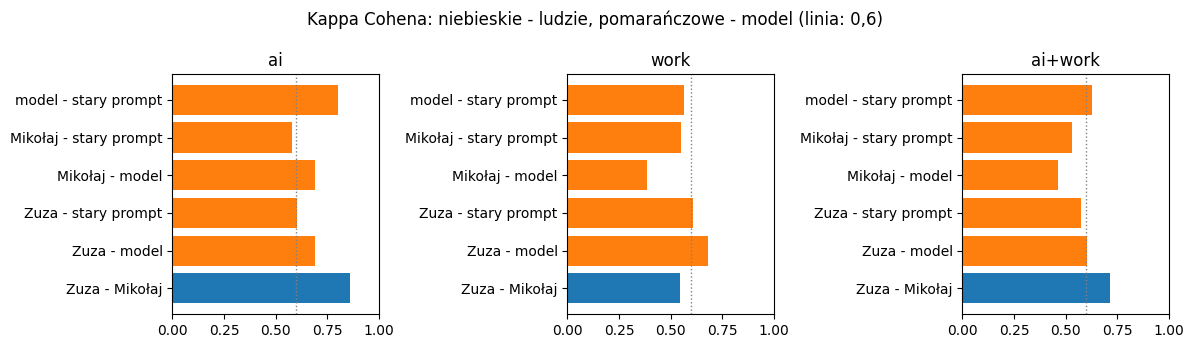

In [8]:
fig, axes = plt.subplots(1, len(ALL_LABELS), figsize=(4 * len(ALL_LABELS), 3.5))
for ax, label in zip(np.atleast_1d(axes), ALL_LABELS):
    part = pairs[pairs["etykieta"] == label]
    colors = np.where(part["rodzaj"] == "z modelem", "tab:orange", "tab:blue")
    ax.barh(part["para"], part["kappa Cohena"], color=colors)
    ax.axvline(0.6, color="grey", ls=":", lw=1)
    ax.set_title(label)
    ax.set_xlim(min(0, part["kappa Cohena"].min() - 0.05), 1)
fig.suptitle("Kappa Cohena: niebieskie - ludzie, pomarańczowe - model (linia: 0,6)")
plt.tight_layout()
plt.savefig(OUT / "cohen_pairs.png", dpi=120)
plt.show()

## 3. Model a etykieta złota

In [9]:
def gold_label(label):
    """Odpowiedź co najmniej dwojga anotatorów; przy dwóch - tylko gdy oboje się zgadzają."""
    votes = pd.concat([ratings[a][label] for a in ANNOTATORS], axis=1)
    result = []
    for row in votes.itertuples(index=False):
        counts = pd.Series(row).dropna().value_counts()
        top = counts.index[0] if len(counts) else None
        ok = len(counts) and counts.iloc[0] >= 2 and (len(counts) == 1 or counts.iloc[1] < counts.iloc[0])
        result.append(top if ok else np.nan)
    return pd.Series(result, dtype=object)


gold = pd.DataFrame({label: gold_label(label) for label in ALL_LABELS})
ratings["złota"] = gold
pd.DataFrame({
    "z etykietą złotą": gold.notna().sum(),
    "bez (spór lub brak)": gold.isna().sum(),
})

,z etykietą złotą,bez (spór lub brak)
ai,139,11
work,121,29
ai+work,132,18


In [10]:
def per_class(truth, predicted, categories):
    rows = []
    for c in categories:
        tp = np.sum((predicted == c) & (truth == c))
        fp = np.sum((predicted == c) & (truth != c))
        fn = np.sum((predicted != c) & (truth == c))
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else np.nan
        rows.append({"kategoria": c, "złota": tp + fn, "model": tp + fp,
                     "precyzja": precision, "czułość": recall, "F1": f1})
    return pd.DataFrame(rows).set_index("kategoria")


MODELS = [r for r in RATERS if r not in ANNOTATORS]
human_mean = pairs[pairs["rodzaj"] == "człowiek - człowiek"].groupby("etykieta")["kappa Cohena"].mean()
rows = []
for name in MODELS:
    for label in [lab for lab in ALL_LABELS if lab in ratings[name].columns]:
        values, _ = labels_of(label, ["złota", name])
        kappa = cohen_kappa(values)
        yes = per_class(values[:, 0], values[:, 1], ["yes"]).iloc[0] if label != "stance" else None
        rows.append({
            "model": name,
            "etykieta": label,
            "wpisów": len(values),
            "trafność": np.mean(values[:, 0] == values[:, 1]),
            "kappa Cohena": kappa,
            "95% CI": bootstrap(cohen_kappa, values),
            "ocena": landis_koch(kappa),
            "precyzja yes": yes["precyzja"] if yes is not None else np.nan,
            "czułość yes": yes["czułość"] if yes is not None else np.nan,
            "kappa ludzi (średnia par)": human_mean.get(label, np.nan),
        })
vs_gold = pd.DataFrame(rows).set_index(["model", "etykieta"])
vs_gold.to_csv(OUT / "model_vs_gold.csv", encoding="utf-8-sig")
vs_gold.round(3)

wpisów  trafność  kappa Cohena        95% CI  \
model        etykieta                                                 
model        ai           139     0.871         0.738  [0.62, 0.85]   
             work         121     0.893         0.694  [0.53, 0.84]   
             ai+work      132     0.841         0.611  [0.46, 0.74]   
stary prompt ai           139     0.813         0.629  [0.50, 0.75]   
             work         121     0.926         0.777  [0.63, 0.90]   
             ai+work      132     0.811         0.597  [0.47, 0.72]   

                             ocena  precyzja yes  czułość yes  \
model        etykieta                                           
model        ai            znaczna         0.758        0.962   
             work          znaczna         0.926        0.935   
             ai+work       znaczna         0.643        0.818   
stary prompt ai            znaczna         0.681        0.942   
             work          znaczna         0.929        0.978   
             ai+work   umiarkowana         0.569        1.000   

                       kappa ludzi (średnia par)  
model        etykieta                             
model        ai                            0.858  
             work                          0.544  
             ai+work                       0.717  
stary prompt ai                            0.858  
             work                          0.544  
             ai+work                       0.717

### Macierze pomyłek i miary per kategoria

In [11]:
for name in MODELS:
    for label in [lab for lab in ALL_LABELS if lab in ratings[name].columns]:
        values, _ = labels_of(label, ["złota", name])
        cats = CATEGORIES[label]
        print(f"\n=== {name}: {label} (wiersze: złota, kolumny: {name})")
        display(pd.crosstab(
            pd.Categorical(values[:, 0], cats), pd.Categorical(values[:, 1], cats),
            rownames=["złota"], colnames=[name], dropna=False,
        ))
        scores = per_class(values[:, 0], values[:, 1], cats)
        scores.to_csv(OUT / f"per_class_{name}_{label}.csv".replace(" ", "_"), encoding="utf-8-sig")
        display(scores.round(3))


=== model: ai (wiersze: złota, kolumny: model)


model,yes,no
złota,,
yes,50,2
no,16,71


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,52,66,0.758,0.962,0.847
no,87,73,0.973,0.816,0.888



=== model: work (wiersze: złota, kolumny: model)


model,yes,no
złota,,
yes,87,6
no,7,21


...

stary prompt,yes,no
złota,,
yes,91,2
no,7,21


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,93,98,0.929,0.978,0.953
no,28,23,0.913,0.750,0.824



=== stary prompt: ai+work (wiersze: złota, kolumny: stary prompt)


stary prompt,yes,no
złota,,
yes,33,0
no,25,74


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,33,58,0.569,1.000,0.725
no,99,74,1.000,0.747,0.855


## 4. Rozbieżności do omówienia

Wpisy, w których model różni się od etykiety złotej, oraz wpisy, przy których anotatorzy się
różnili. Zapisujemy je do folderu wyników.

In [12]:
def show(mask, labels):
    columns = {}
    for label in labels:
        for rater in [*raters_for(label), "złota"]:
            if label in ratings[rater].columns:
                columns[f"{label}: {rater}"] = ratings[rater][label]
    view = pd.DataFrame({
        "url": base["url"],
        "text": base["text"].str.replace("\n", " ").str.slice(0, 300),
        **columns,
    })
    return view[mask.to_numpy()]


model_labels = [lab for lab in ALL_LABELS if lab in model.columns]
model_split = pd.Series(False, index=base.index)
for label in model_labels:
    model_split |= gold[label].notna() & model[label].ne(gold[label])
human_split = pd.Series(False, index=base.index)
for label in LABELS:
    votes = pd.concat([ratings[a][label] for a in ANNOTATORS], axis=1)
    human_split |= votes.nunique(axis=1, dropna=False) > 1
print("model inaczej niż złota:", model_split.sum(), "| anotatorzy niezgodni:", human_split.sum())

show(model_split, model_labels).to_csv(OUT / "model_vs_gold_rows.csv", encoding="utf-8-sig")
show(human_split, LABELS).to_csv(OUT / "annotators_split.csv", encoding="utf-8-sig")
show(model_split, model_labels)

model inaczej niż złota: 30 | anotatorzy niezgodni: 39


,url,text,ai: Zuza,ai: Mikołaj,ai: model,ai: stary prompt,ai: złota,work: Zuza,work: Mikołaj,work: model,work: stary prompt,work: złota,ai+work: Zuza,ai+work: Mikołaj,ai+work: model,ai+work: stary prompt,ai+work: złota
1,https://wykop.pl/wpis/42626475/code-review-dlaczego-warto-praktykowac-i-jak-ideal,"[Code review – dlaczego warto praktykować i jak idealnie zaplanować przegląd kodu](https://www.dobreprogramy.pl/Code-review-dlaczego-warto-praktykowac-i-jak-idealnie-zaplanowac-przeglad-kodu,News,...",no,no,no,no,no,yes,yes,no,no,yes,no,no,no,no,no
7,https://wykop.pl/wpis/47291369/czesc-lapcie-nowe-oferty-na-jobsforgeek-dla-backen,"Cześć, łapcie nowe oferty na JobsForGeek dla #Backend: #Zdalnie: Python Developer - 100% REMOTE ASTEK Polska 15456 - 15792 PLN/m netto ➡ https://jobsforgeek.com/job-offers/details/168318 Backen...",no,no,yes,yes,no,yes,yes,yes,yes,yes,no,no,yes,yes,no
8,https://wykop.pl/wpis/74058605/lol-wlasnie-nie-przedluzylem-gosciowi-kontraktu-da,"LOL, właśnie nie przedłużyłem gościowi kontraktu (Data Scientist) - bo się jąkał. Co za idiotyczny powód. Bombardował każde daily, nie dało się z nim komunikować. Ciekawe jak przeszedł rekrutacje....",no,no,yes,yes,no,yes,yes,yes,yes,yes,no,no,yes,yes,no
10,https://wykop.pl/wpis/75760285/czy-u-was-w-firmie-zaproponowali-wam-esop-employee,"Czy u Was w firmie zaproponowali Wam ESOP (Employee Stock Option Plan)? Dobrze rozumiem, że abym cokolwiek z tego miał, muszę po vestingu wyłożyć własne pieniądze aby te udziały formalnie nabyć? (...",no,no,yes,no,no,yes,yes,yes,yes,yes,no,no,yes,no,no
12,https://wykop.pl/wpis/86964503/niemal-30-mniej-osob-niz-rok-temu-wybralo-informat,"Niemal 30% mniej osób niż rok temu wybrało informatykę na kierunek studiów Żaden inny kierunek nie zaliczył takiego spadku Mocno za to w górę kierunki społeczne, opierające się na pomocy drugiem...",yes,yes,yes,yes,yes,yes,yes,no,yes,yes,yes,yes,no,yes,yes
14,https://wykop.pl/wpis/75175239/ai-idzie-po-wasze-stolki-ai-sztucznainteligencja-g,AI idzie po wasze stołki #ai #sztucznainteligencja #gpt,yes,yes,yes,yes,yes,yes,yes,no,yes,yes,yes,yes,no,yes,yes
19,https://wykop.pl/wpis/66818215/gralem-sobie-wczoraj-w-csgo-pojawil-sie-jakis-chlo,"Gralem sobie wczoraj w #csgo. Pojawil sie jakis chlopaczek, pogadalismy co tam jak tam. Ma wakacje, lubi sobie popykac w csa, niestety ma slabego kompa bo aktualnie mieszka sam z mama i ledwo daja...",no,no,no,no,no,no,no,yes,yes,no,no,no,no,no,no
24,https://wykop.pl/wpis/70476871/jak-sie-czujecie-z-tym-ze-sztuczna-inteligencja-wk,"Jak się czujecie z tym, że sztuczna inteligencja wkrótce zabierze lwią część rynku p---o kobietom? #p---o #sztucznainteligencja #redpill #blackpill #bluepill #p0lka #ankieta #wincyjtagow #sexwork ...",yes,yes,yes,yes,yes,yes,yes,no,yes,yes,yes,yes,no,yes,yes
42,https://wykop.pl/wpis/49387457/zapraszamy-na-srodowy-przeglad-ofert-pracy-z-kateg,"Zapraszamy na środowy przegląd ofert pracy z kategorii **Mobile**, **Testing** i **DevOps**! **MOBILE JOBS** - [REMOTE] [Remote Android Engineer](https://nofluffjobs.com/DLRJVX5HW) @ linkgroup.p...",no,no,yes,yes,no,yes,yes,yes,yes,yes,no,no,yes,yes,no
52,https://wykop.pl/wpis/79049631/kalend-czy-moczend-gdzie-teraz-latwiej-dostac-20k-,"Kałend czy moczend, gdzie teraz łatwiej dostać 20k jako junior po bootcampie? #pytanie #programowanie #pracait #programista20k",no,no,yes,yes,no,yes,yes,yes,yes,yes,no,no,yes,yes,no


In [13]:
show(human_split, LABELS)

,url,text,ai: Zuza,ai: Mikołaj,ai: model,ai: stary prompt,ai: złota,work: Zuza,work: Mikołaj,work: model,work: stary prompt,work: złota
18,https://wykop.pl/wpis/83768033/tez-tak-macie-ze-jak-odchodzicie-od-kompa-np-do-ki,"Też tak macie, że jak odchodzicie od kompa np do kibla to mówicie sami do siebie coś w stylu - Hej, hej zasobie B2B, nie pomyliło ci się coś? #programista15k #pytanie #pracait #korposwiat #prac...",no,no,no,yes,no,yes,no,yes,yes,NaN
23,https://wykop.pl/wpis/41825341/jak-myslicie-jakie-w-przyszlosci-beda-lukratywne-z,"jakie macie teorie co do tego jakie w przyszłości będą lukratywne zawody? ! pomijając rzeczy typu lekarz, programista, czy podobne xD mówię tu o nowych zawodach, które będą przynosić całkiem niezł...",no,yes,yes,yes,NaN,yes,yes,yes,yes,yes
27,https://wykop.pl/wpis/84333657/ej-aj-juz-przescignela-czlowieka-wiec-moze-sobie-p,Ej Aj już prześcignęła człowieka więc może sobie pozwolić na błędy ortograficzne #programista15k #pracait,yes,yes,yes,yes,yes,yes,no,yes,yes,NaN
29,https://wykop.pl/wpis/59797329/zaczynam-zastanawiac-sie-czy-nie-lepiej-by-sie-zyl,Zaczynam zastanawiać się czy nie lepiej by się żyło jakby przebranżowić z senior deva na devopsing na który jest teraz ogromne ssanie na rynku. + nie musisz mieć wiedzy domenowej/biznesowej o pr...,yes,no,no,no,NaN,yes,yes,yes,yes,yes
31,https://wykop.pl/wpis/85142085/wychodzi-na-to-ze-taki-sredni-influ-majacy-przycho,"Wychodzi na to, że taki średni influ mający przychód ok 50 k, każdego miesiąca płaci ok 15 k za mało podatków od średniej (czyli tyle mu dokłądamy), super k---a XDDD Jak dobrze, że US ścigają jaki...",no,no,no,no,no,yes,no,yes,yes,NaN
33,https://wykop.pl/wpis/71197423/chatgpt-pomoze-ludziom-korzystac-po-prostu-z-kompu,"ChatGPT pomoże ludziom korzystać... po prostu z komputerów. Wiele rzeczy można by robić za pomocą dosyć prostych algorytmów, ale najpierw musiałoby tobie, specjaliście w wąskiej dziedzinie, w ogól...",yes,yes,yes,yes,yes,no,yes,no,yes,NaN
34,https://wykop.pl/wpis/86768775/skrot-dzisiejszych-wiadomosci-ze-swiata-technologi,Skrót dzisiejszych wiadomości ze świata technologii #codziennytech #sztucznainteligencja #technologia #wydarzenia #komputery #informatyka #ciekawostki #programowanie #gruparatowaniapoziomu Uwaga: ...,yes,yes,yes,yes,yes,yes,no,yes,yes,NaN
36,https://wykop.pl/wpis/83480301/niesamowita-nowosc-na-allegro-i-od-razu-niesamowit,Niesamowita nowość na allegro I od razu niesamowite propozycje abym oszczędził na przesyłce ( ͡° ͜ʖ ͡°) Jakież do szkoły trzeba kończyć żeby takie algorytmy tworzyć (ʘ‿ʘ) #allegro #heheszki #sz...,yes,yes,yes,yes,yes,no,yes,no,yes,NaN
39,https://wykop.pl/wpis/63462353/etykiety-samoprzylepne-macie-moze-wsrod-rodziny-lu,"ETYKIETY SAMOPRZYLEPNE Macie może wśród rodziny lub znajomych kogoś kto korzysta przy produkcji jakiegoś towaru z etykiet? Lub czy wpadają wam do głowy jakieś firmy, które dużo ich zużywają? #prac...",no,no,no,no,no,yes,no,yes,yes,NaN
44,https://wykop.pl/wpis/87877607/banda-npc-wierzy-w-szybki-zarobek-poprzez-poklikan,"- Banda NPC wierzy w szybki zarobek poprzez poklikanie w konkuter mimo żadnych kwalifikacji. - Każdy próboje mimo że udało się może promilowi chętnych coś zarobić, ale TO ON BĘDZIE TYM CO ZAROBI M...",yes,no,yes,yes,NaN,yes,yes,yes,yes,yes


## Jak czytać wyniki

- **Ludzie między sobą.** Kappa powyżej 0,8 to zgodność prawie pełna, 0,6-0,8 znaczna
  (Landis i Koch 1977). Jeśli jest niska, problemem jest definicja etykiety, nie model -
  najpierw doprecyzujcie wytyczne na podstawie listy rozbieżności.
- **Model.** Jeśli kappa model-człowiek mieści się w zakresie kapp człowiek-człowiek, model
  może zastąpić anotatora. Jeśli jest wyraźnie niższa, trzeba poprawić prompt albo model.
- **`ai+work`** to filtr do dalszej analizy: precyzja mówi, ile przepuszczonych wpisów jest
  zbędnych, czułość - ile właściwych wpisów odpada.
- Kappa przy rzadkich kategoriach bywa niska mimo wysokiej zgodności procentowej - wtedy
  patrz też na liczby w macierzy pomyłek.